# Used Car Price Prediction in Pakistan (PakWheels)

**Module 3 ML Project**

**GitHub repo:** _paste your repo link here_

Dataset: PakWheels used car listings (about 77,000 ads scraped from pakwheels.com).

## 1. Problem statement

**Predict** the asking price (PKR) of a used car **for** buyers and sellers on PakWheels **using** the car's make, model, year, engine size, mileage, transmission, fuel type, body type, assembly (local or imported), colour, city and registration city, **so that** a seller can set a fair price for an ad and a buyer can tell if a listed price is too high.

- **Label:** `price` (a number), so this is a **regression** problem.
- **Metrics:** MAE (average error in rupees, easy to explain) and R² (how much of the price variation the model explains).

## 2. Data
First I import the libraries for data handling, plotting and modelling.

In [1]:
# Data handling
import numpy as np
import pandas as pd

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns

# Modelling (scikit-learn)
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

import warnings
warnings.filterwarnings('ignore')

# Display settings so tables and charts are easy to read
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

I load the dataset. The original `pakwheels_used_cars.csv` had a broken `year` column (every row said 1905), so I use `pakwheels_used_car_data_v02.csv`. It has the same ads with real years, and year is one of the most important features for car price.

In [2]:
# Load the correct version of the data (v02 has real years)
df = pd.read_csv('pakwheels_used_car_data_v02.csv')
df.head()

,addref,city,assembly,body,make,model,year,engine,transmission,fuel,color,registered,mileage,price
0,7943732,Peshawar,NaN,Sedan,Toyota,Corolla,"2,013.00","1,300.00",Manual,Petrol,Silver Metallic,Lahore,145000,"2,870,000.00"
1,7730314,Lahore,NaN,Sedan,Honda,City,"2,000.00","1,300.00",Manual,Petrol,Blue,Lahore,230000,"995,000.00"
2,7943737,Lahore,NaN,Sedan,Toyota,Yaris,"2,021.00","1,300.00",Manual,Petrol,Super White,Punjab,60500,"3,585,000.00"
3,7943733,Lahore,NaN,Hatchback,Suzuki,Swift,"2,017.00","1,300.00",Manual,Petrol,Grey,Islamabad,87000,"2,250,000.00"
4,7923484,Lahore,NaN,Sedan,Honda,Civic,"2,017.00","1,800.00",Automatic,Petrol,Grey,Lahore,86000,"4,850,000.00"


I check the shape (rows, columns), the column names and the data types.

In [3]:
# Number of rows and columns
print('Shape:', df.shape)

# Column names and data types
df.info()

Shape: (77878, 14)
<class 'pandas.DataFrame'>
RangeIndex: 77878 entries, 0 to 77877
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   addref        77878 non-null  int64  
 1   city          77878 non-null  str    
 2   assembly      24189 non-null  str    
 3   body          68974 non-null  str    
 4   make          77878 non-null  str    
 5   model         77878 non-null  str    
 6   year          73099 non-null  float64
 7   engine        77875 non-null  float64
 8   transmission  77878 non-null  str    
 9   fuel          76972 non-null  str    
 10  color         76398 non-null  str    
 11  registered    77878 non-null  str    
 12  mileage       77878 non-null  int64  
 13  price         77295 non-null  float64
dtypes: float64(3), int64(2), str(9)
memory usage: 12.5 MB


I look at summary statistics to spot odd values, for example a 3cc engine or a 1,000,000 km mileage.

In [4]:
# Summary of numeric and text columns
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
addref,"77,878.00",NaN,NaN,NaN,"7,809,878.24","259,952.29","274,897.00","7,805,759.75","7,865,805.00","7,910,333.75","7,943,741.00"
city,77878,297,Lahore,16674,NaN,NaN,NaN,NaN,NaN,NaN,NaN
assembly,24189,1,Imported,24189,NaN,NaN,NaN,NaN,NaN,NaN,NaN
body,68974,21,Sedan,30193,NaN,NaN,NaN,NaN,NaN,NaN,NaN
make,77878,68,Toyota,24910,NaN,NaN,NaN,NaN,NaN,NaN,NaN
model,77878,435,Corolla,12871,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,"73,099.00",NaN,NaN,NaN,"2,012.81",7.52,"1,990.00","2,007.00","2,015.00","2,019.00","2,022.00"
engine,"77,875.00",NaN,NaN,NaN,"1,408.07",704.46,3.00,"1,000.00","1,300.00","1,600.00","15,000.00"
transmission,77878,2,Automatic,42763,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fuel,76972,3,Petrol,70620,NaN,NaN,NaN,NaN,NaN,NaN,NaN


I count missing values in each column and check for duplicate rows.

In [5]:
# Missing values: count and percentage per column
missing = pd.DataFrame({
    'missing_count': df.isna().sum(),
    'missing_%': (df.isna().mean() * 100).round(2)
}).sort_values('missing_count', ascending=False)
print(missing)

# Duplicate rows
print('\nDuplicate rows:', df.duplicated().sum())

              missing_count  missing_%
assembly              53689      68.94
body                   8904      11.43
year                   4779       6.14
color                  1480       1.90
fuel                    906       1.16
price                   583       0.75
engine                    3       0.00
make                      0       0.00
addref                    0       0.00
city                      0       0.00
model                     0       0.00
transmission              0       0.00
registered                0       0.00
mileage                   0       0.00

Duplicate rows: 0


**What I found:**
- `assembly` is 69% missing, but its only value is "Imported". On PakWheels a blank here means the car is **locally assembled**, so I fill it with "Local". This is a fixed rule per row, not something learned from the data, so it does not cause leakage.
- `price` is missing for 583 rows. We cannot train on rows with no label, so I drop them.
- `year`, `body`, `fuel`, `color` and `engine` have some missing values. I fill these **inside the Pipeline** (step 5), so the fill values come from the training data only.

### Basic cleaning (row rules only, nothing learned from the data)
I apply simple cleaning that only looks at one row at a time, so it is safe to do before the split:
- Fill `assembly` with "Local".
- Drop rows with no price.
- Drop impossible engine sizes (below 600cc or above 6600cc). These are typing mistakes in the ads.
- Drop prices above 200M PKR. The only one is a 2021 Corolla listed at 529M PKR, which is clearly a typo.
- Group over 380 colour spellings (e.g. "Super white", "Pearl White") into base colours.
- Drop `addref`, because it is just an ad ID and tells us nothing about price.

In [6]:
data = df.copy()

# 1) A blank assembly means a locally assembled car
data['assembly'] = data['assembly'].fillna('Local')

# 2) Rows without a label cannot be used for training
data = data.dropna(subset=['price'])

# 3) Remove impossible engine sizes (keep NaN, the pipeline will impute them)
bad_engine = (data['engine'] < 600) | (data['engine'] > 6600)
print('Rows with impossible engine size removed:', bad_engine.sum())
data = data[~bad_engine]

# 3b) Remove the obvious price typo (a 2021 Corolla listed at 529M PKR)
print('Rows with price above 200M removed:', (data['price'] > 2e8).sum())
data = data[data['price'] <= 2e8]

# 4) Simplify colour names into base colours
base_colours = ['white', 'black', 'grey', 'gray', 'silver', 'red', 'blue', 'green',
                'brown', 'yellow', 'orange', 'gold', 'beige', 'bronze', 'maroon']
def simplify_colour(c):
    if pd.isna(c):
        return np.nan                     # leave missing for the pipeline
    c = c.lower()
    for base in base_colours:
        if base in c:
            return 'Grey' if base == 'gray' else base.capitalize()
    return 'Other'
data['color'] = data['color'].apply(simplify_colour)

# 5) Drop the ad ID column
data = data.drop(columns=['addref'])

print('Shape after cleaning:', data.shape)
print('Colour groups:', data['color'].nunique())

Rows with impossible engine size removed: 207
Rows with price above 200M removed: 1


Shape after cleaning: (77087, 13)
Colour groups: 15


## 3. Exploratory Data Analysis (EDA)
I start with the label. Car prices are usually **right-skewed**: most cars are cheap and a few luxury cars cost a lot. I plot price on the normal scale and on a log scale.

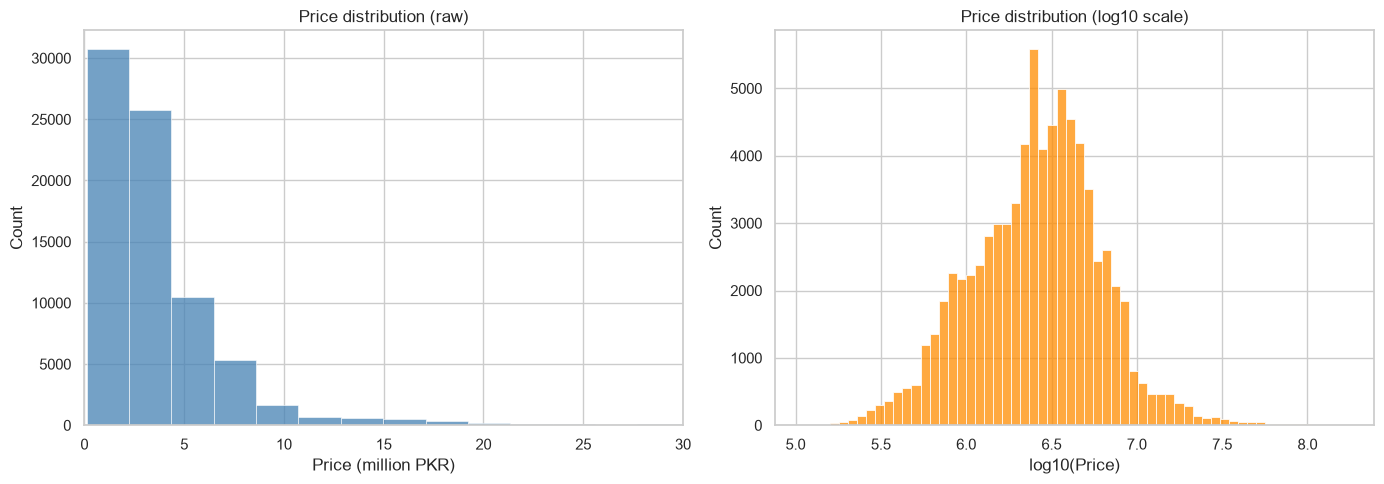

count         77,087
mean       3,825,028
std        5,160,807
min          110,000
25%        1,450,000
50%        2,700,000
75%        4,500,000
max      170,000,000
Name: price, dtype: str


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Raw price (in millions of PKR for readability)
sns.histplot(data['price'] / 1e6, bins=80, ax=axes[0], color='steelblue')
axes[0].set_title('Price distribution (raw)')
axes[0].set_xlabel('Price (million PKR)')
axes[0].set_xlim(0, 30)

# Log price
sns.histplot(np.log10(data['price']), bins=60, ax=axes[1], color='darkorange')
axes[1].set_title('Price distribution (log10 scale)')
axes[1].set_xlabel('log10(Price)')

plt.tight_layout()
plt.show()

print(data['price'].describe().apply(lambda x: f'{x:,.0f}'))

**Observation:** Price is very right-skewed (median 2.7M PKR, but the most expensive ads reach 170M PKR). On the log scale it looks close to a bell curve. So I will train the models on **log(price)**, which stops the few very expensive cars from dominating the errors, then convert predictions back to rupees.

I check how price changes with manufacturing year. I expect newer cars to cost more.

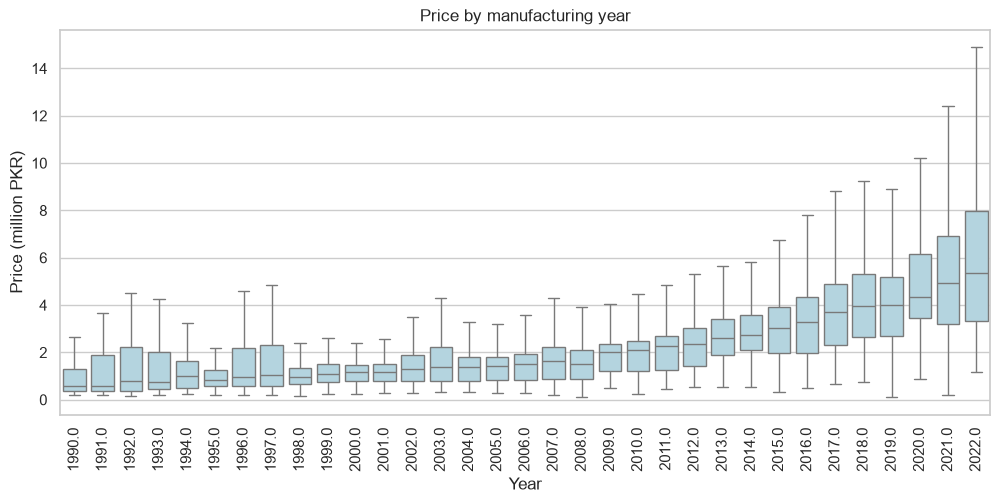

In [8]:
# Median price per year
yearly = data.groupby('year')['price'].median() / 1e6

plt.figure(figsize=(12, 5))
sns.boxplot(data=data, x='year', y=data['price'] / 1e6, showfliers=False, color='lightblue')
plt.title('Price by manufacturing year')
plt.xlabel('Year')
plt.ylabel('Price (million PKR)')
plt.xticks(rotation=90)
plt.show()

**Observation:** Price goes up clearly with year. Cars from 2018 onwards are much more expensive. Year will be a strong feature.

I compare prices across the 10 most common makes, because the brand matters a lot.

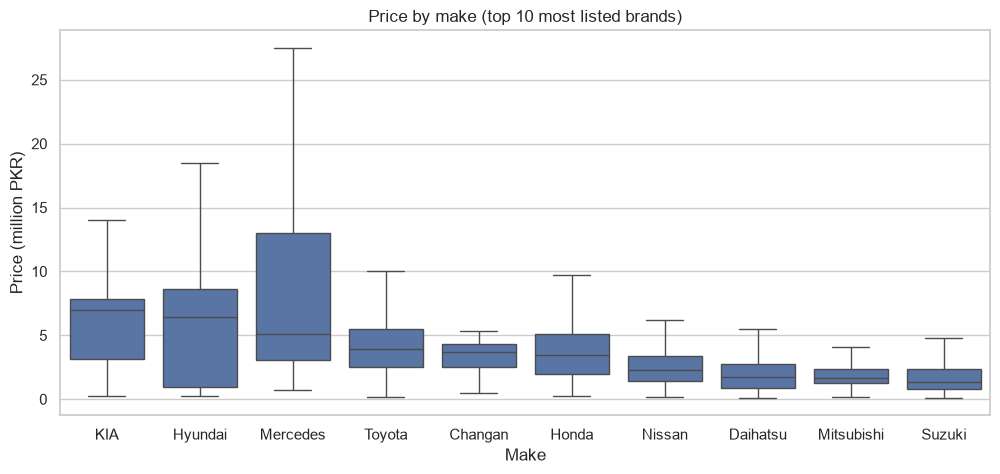

make
Toyota        24611
Suzuki        22279
Honda         16336
Daihatsu       3166
KIA            1750
Nissan         1513
Hyundai        1461
Mitsubishi     1094
Changan         937
Mercedes        575
Name: count, dtype: int64


In [9]:
top_makes = data['make'].value_counts().head(10).index
subset = data[data['make'].isin(top_makes)]
order = subset.groupby('make')['price'].median().sort_values(ascending=False).index

plt.figure(figsize=(12, 5))
sns.boxplot(data=subset, x='make', y=subset['price'] / 1e6, order=order, showfliers=False)
plt.title('Price by make (top 10 most listed brands)')
plt.xlabel('Make')
plt.ylabel('Price (million PKR)')
plt.show()

# How many ads per make
print(data['make'].value_counts().head(10))

**Observation:** Toyota, Suzuki and Honda make up most ads. Suzuki and Daihatsu are cheap small cars, while KIA, Hyundai and Toyota cost more. Make and model will be important.

I check how mileage relates to price. More km driven should mean a lower price.

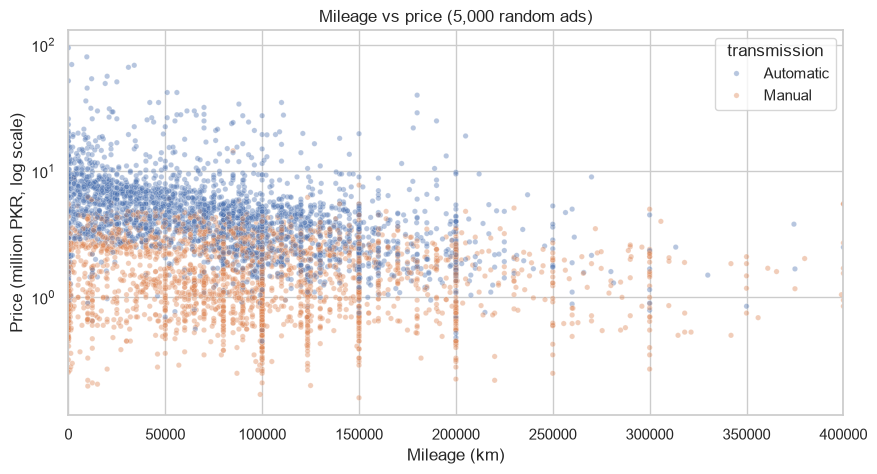

In [10]:
sample = data.sample(5000, random_state=42)   # sample so the plot is not overcrowded

plt.figure(figsize=(10, 5))
sns.scatterplot(data=sample, x='mileage', y=sample['price'] / 1e6, hue='transmission', alpha=0.4, s=15)
plt.yscale('log')
plt.xlim(0, 400000)
plt.title('Mileage vs price (5,000 random ads)')
plt.xlabel('Mileage (km)')
plt.ylabel('Price (million PKR, log scale)')
plt.show()

**Observation:** Higher mileage tends to mean a lower price, but the spread is wide. Automatic cars (orange) are generally priced higher than manual ones.

I compare price by transmission, assembly and fuel type.

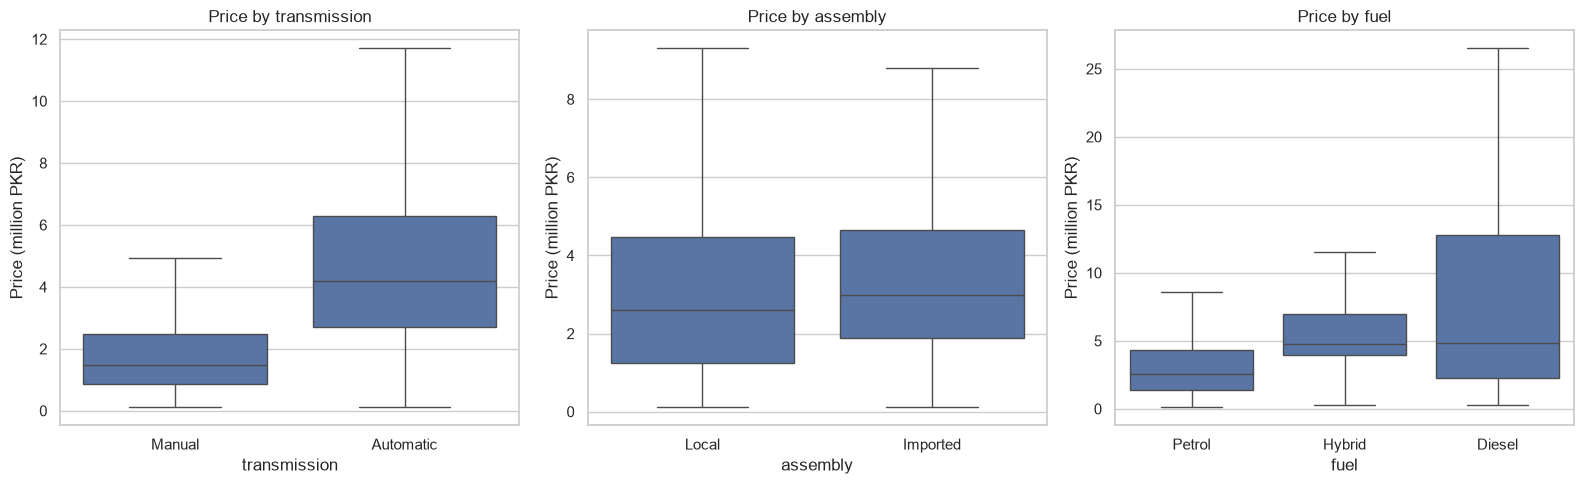

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col in zip(axes, ['transmission', 'assembly', 'fuel']):
    sns.boxplot(data=data, x=col, y=data['price'] / 1e6, showfliers=False, ax=ax)
    ax.set_title(f'Price by {col}')
    ax.set_ylabel('Price (million PKR)')
plt.tight_layout()
plt.show()

**Observation:** Automatic, imported and hybrid/diesel cars sell for more. Each of these columns gives the model useful information.

I check how the numeric features correlate with price (using log price, since that is what the model will learn).

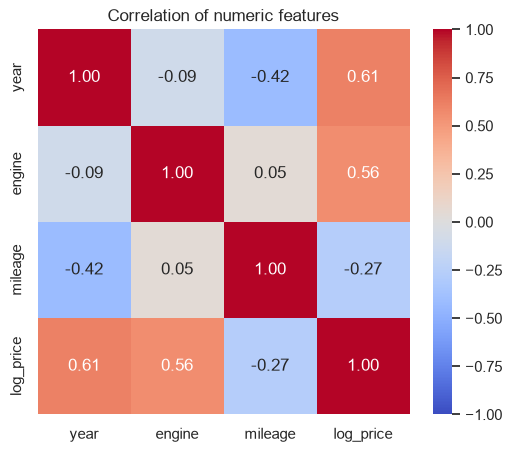

In [12]:
num = data[['year', 'engine', 'mileage']].copy()
num['log_price'] = np.log10(data['price'])

plt.figure(figsize=(6, 5))
sns.heatmap(num.corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation of numeric features')
plt.show()

**Observation:** Year (+) and engine size (+) have the strongest links to price, and mileage is negative. Year and mileage are also linked to each other, because older cars have driven more.

## 4. Train/test split and baseline
I split the data **before** any learned preprocessing: 80% train, 20% test, `random_state=42`. The test set stays untouched until the final evaluation.

In [13]:
# Features (X) and label (y)
X = data.drop(columns=['price'])
y = data['price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (61669, 12)  Test: (15418, 12)


**Baseline:** a model that always predicts the **median training price** for every car. Any real model must beat this to be useful. I use the median because it is less affected by the very expensive cars than the mean.

In [14]:
baseline = DummyRegressor(strategy='median')
baseline.fit(X_train, y_train)
base_pred = baseline.predict(X_test)

baseline_mae = mean_absolute_error(y_test, base_pred)
baseline_r2 = r2_score(y_test, base_pred)
print(f'Baseline prediction for every car: {base_pred[0]:,.0f} PKR')
print(f'Baseline MAE: {baseline_mae:,.0f} PKR')
print(f'Baseline R2 : {baseline_r2:.3f}')

Baseline prediction for every car: 2,700,000 PKR
Baseline MAE: 2,354,477 PKR
Baseline R2 : -0.043


The baseline is off by about 2.3M PKR per car on average and its R² is just below 0, so it explains nothing. This is the score to beat.

## 5. Preprocessing Pipeline (no leakage)
I build all preprocessing into a `ColumnTransformer` inside a `Pipeline`, so imputers, encoders and scalers are **fitted on the training folds only**, and cross-validation stays honest.
- **Numeric** (`year`, `engine`, `mileage`): fill missing values with the median, then scale.
- **Categorical** (`make`, `model`, `city`, ...): fill missing values with "Unknown", then one-hot encode. Rare categories (fewer than 20 ads) are grouped into one "infrequent" column, and unseen categories in the test set are handled without errors.
- **Target:** `TransformedTargetRegressor` trains on `log(price)` and converts predictions back to PKR, so MAE is still in rupees.

In [15]:
numeric_features = ['year', 'engine', 'mileage']
categorical_features = ['city', 'assembly', 'body', 'make', 'model',
                        'transmission', 'fuel', 'color', 'registered']

# Steps for numeric columns
numeric_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Steps for categorical columns
categorical_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
    ('onehot', OneHotEncoder(handle_unknown='infrequent_if_exist',
                             min_frequency=20, sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipe, numeric_features),
    ('cat', categorical_pipe, categorical_features)
])

def make_model(regressor):
    """Preprocessing + regressor in one pipeline, trained on log(price)."""
    pipe = Pipeline([('prep', preprocessor), ('model', regressor)])
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)

# Check how many columns the preprocessing creates (fitted on train only)
n_cols = preprocessor.fit(X_train).transform(X_train.head()).shape[1]
print('Number of features after encoding:', n_cols)

Number of features after encoding: 371
